In [1]:
%% Homework 3
% Ely Dawson
% Due: 22 Oct 2026

Executing ...

In [27]:
%% 1: Plot the time series of wind speed, wave height, water temperature, 
% and air temperature from 46047. Since the data are text files with a
% header, in Matlab you can read with: importdata
% Read the help page. You’ll want to specify a blank space delimiter between files
% and 2 header lines.

%% How are missing data identified in the records?
% The missing data is filled by using either 99 or 999 entry values. 
% They are using numbers so unbelievably large that there is no mistake on if it is real entry. 
% Wave height definitely has the most missing data points of the three variables. 
% The graphs are a little silly to look at. 

In [62]:
file15 = '46047h2015.txt';
file16 = '46047h2016.txt';
dlim = ' ';
header = 2;

T15 = importdata(file15, dlim, header);
T16 = importdata(file16, dlim, header);

% continuous record
T = [T15.data; T16.data];
data = T;
T = struct();
T.data = data;
T.date = datetime(T.data(:,1), T.data(:,2), T.data(:,3), T.data(:,4), T.data(:,5), 0, 'TimeZone', 'UTC');
T.posix = posixtime(T.date);
T.wspd = T.data(:,7);
T.wvht = T.data(:,9);
T.wtmp = T.data(:,15);
T.atmp = T.data(:,14);

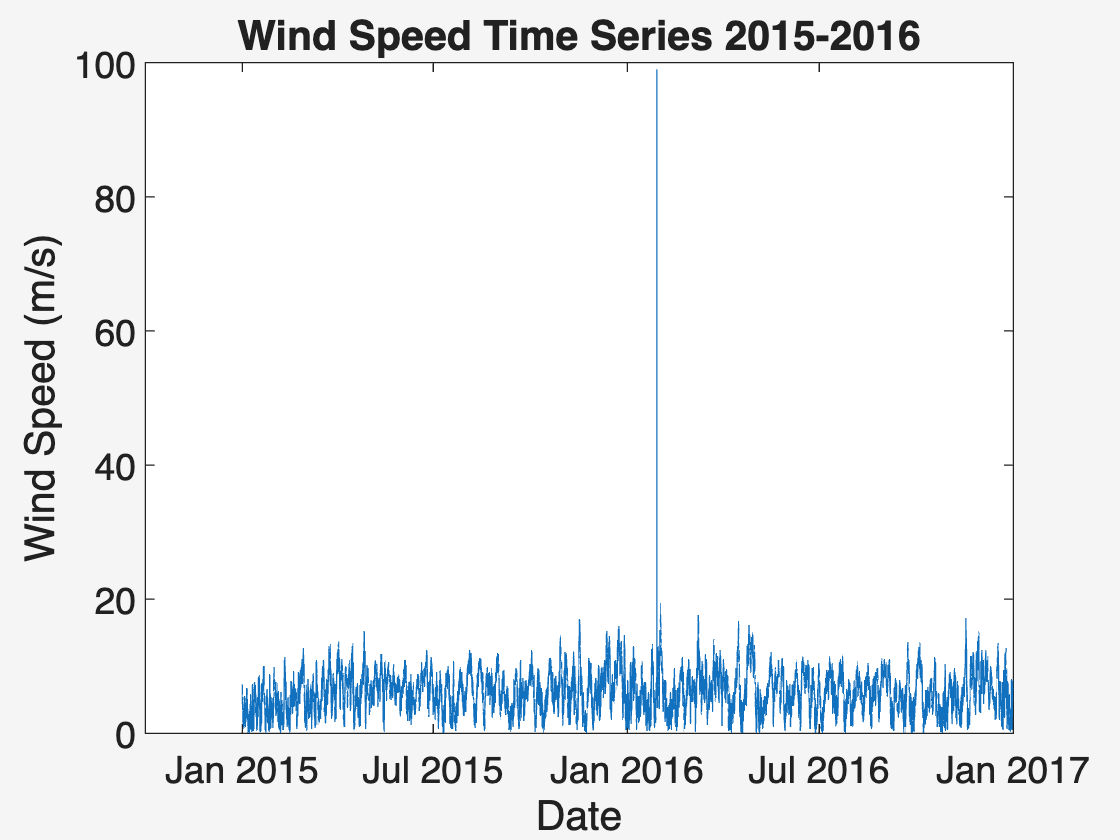

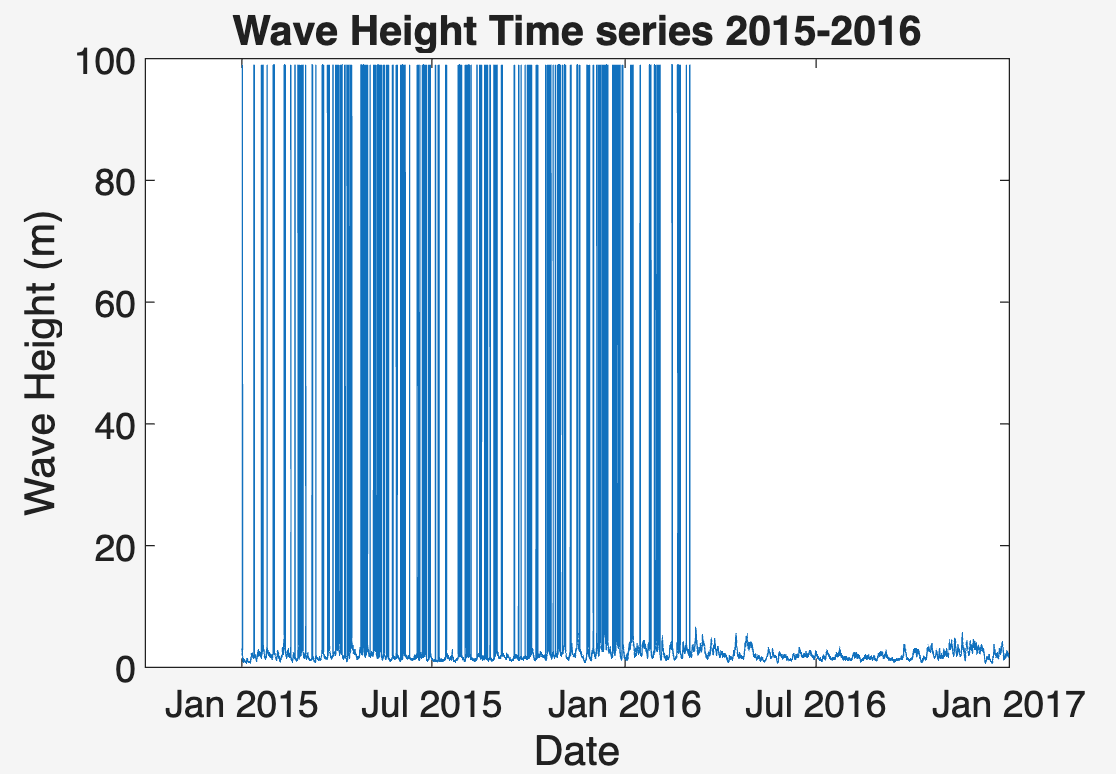

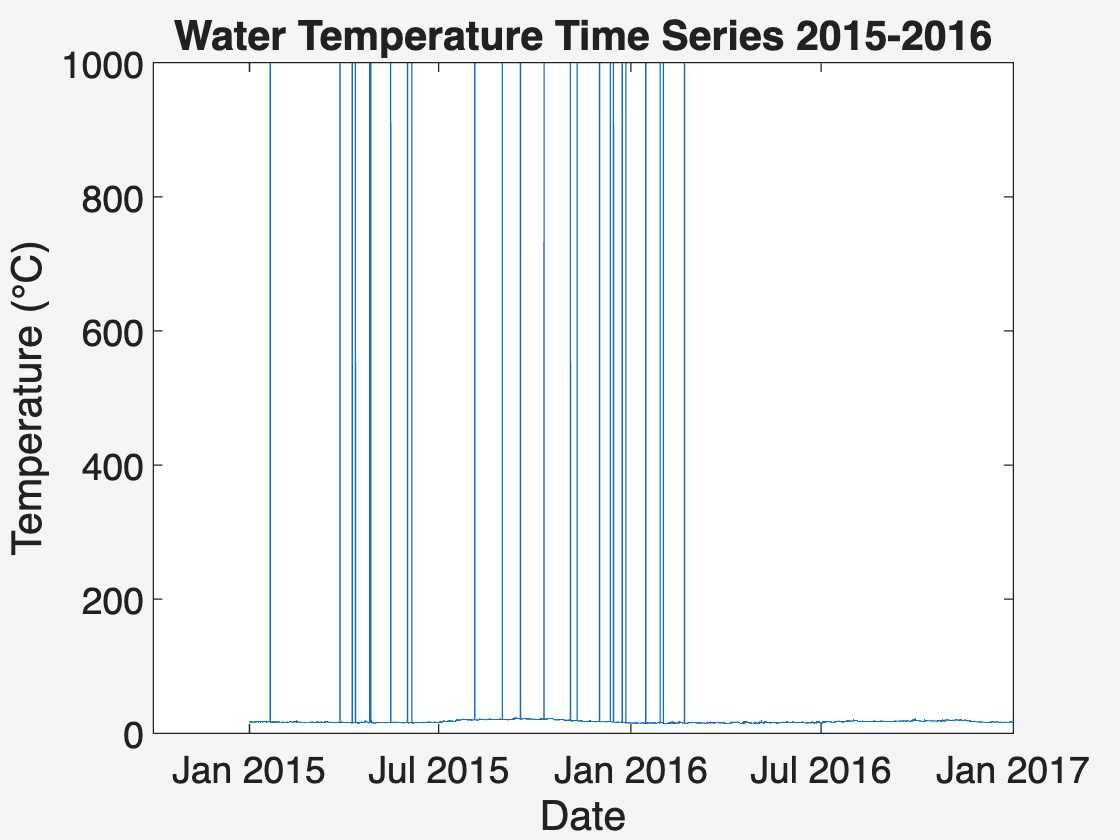

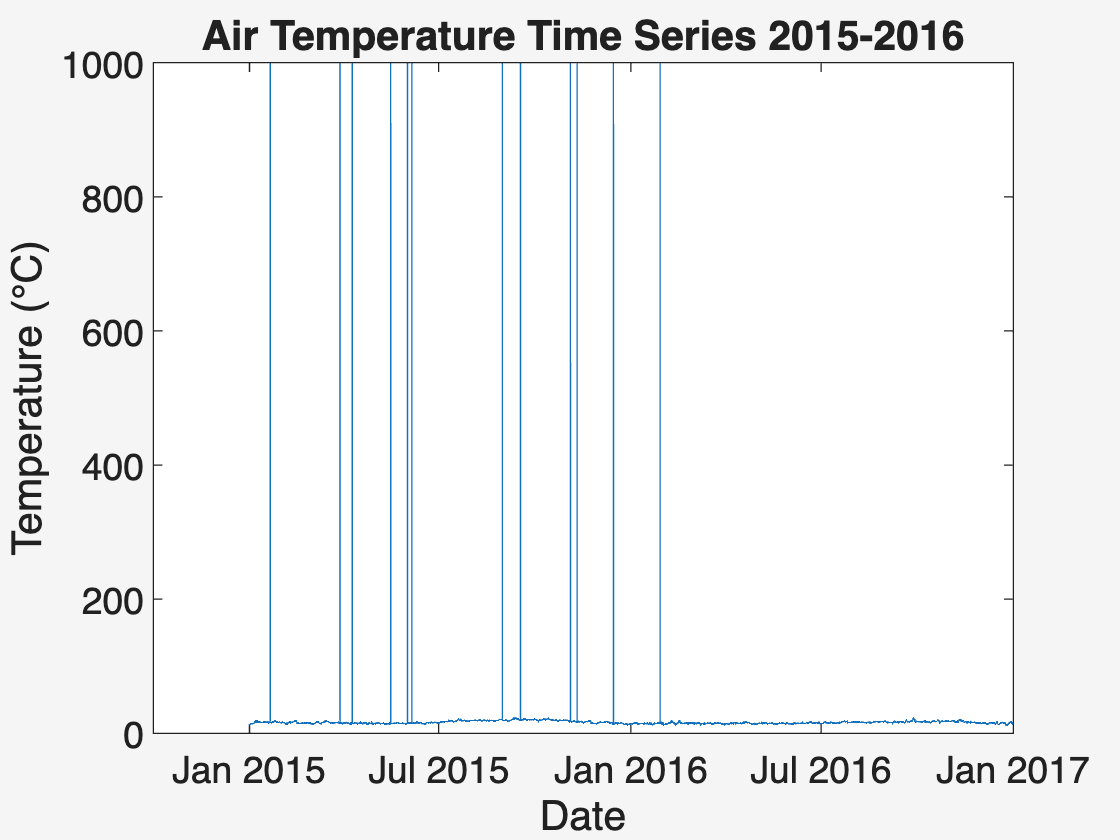

In [65]:
% Plot the time series for wind speed, wave height, water temp
figure (1); clf;
plot(T.date, T.wspd);
title('Wind Speed Time Series 2015-2016');
ylabel('Wind Speed (m/s)')
xlabel('Date')

figure (2); clf;
plot(T.date, T.wvht);
title('Wave Height Time series 2015-2016');
ylabel('Wave Height (m)')
xlabel('Date')

figure(3); clf;
plot(T.date, T.wtmp);
title('Water Temperature Time Series 2015-2016');
ylabel('Temperature (°C)')
xlabel('Date')

figure(4); clf;
plot(T.date, T.atmp);
title('Air Temperature Time Series 2015-2016');
ylabel('Temperature (°C)')
xlabel('Date')

In [30]:
%% 2: Monthly means. 
% Since there’s quite a bit of variability, average the data to
% produce monthly means for 2015 and 2016. Plot the means for each month and
% standard error of the mean. Data are provided at varying frequencies, but consecutive 
% data are not independent. For the purposes of this problem set, let’s assume
% that the data provide one independent sample every 7 days. Hint: In Matlab, use: errorbar
% to plot the data with uncertainty ranges.

In [66]:
T.wspd(T.wspd == 99) = nan;
T.wvht(T.wvht == 99) = nan;
T.wtmp(T.wtmp == 999) = nan;
T.atmp(T.atmp == 999) = nan;

years = [2015, 2016];
m_mean_wspd = nan(12,2);
m_mean_wvht = nan(12,2);
m_mean_wtmp = nan(12,2);
m_mean_atmp = nan(12,2);
m_sem_wspd = nan(12,2);
m_sem_wvht = nan(12,2);
m_sem_wtmp = nan(12,2);
m_sem_atmp = nan(12,2);

for k = 1:numel(years)
    for m = 1:12
        idx = year(T.date) == years(k) & month(T.date) == m;
        values = T.wspd(idx);
        values = values(isfinite(values));
        m_mean_wspd(m,k) = mean(values);
        n = numel(values);
        dm = day(datetime(years(k),m+1,1) - caldays(1));
        nind = min(n, dm / 7);
        m_sem_wspd(m,k) = std(values) / sqrt(nind);
    end
end

for k = 1:numel(years)
    for m = 1:12
        idx = year(T.date) == years(k) & month(T.date) == m;
        values = T.wvht(idx);
        values = values(isfinite(values));
        m_mean_wvht(m,k) = mean(values);
        n = numel(values);
        dm = day(datetime(years(k),m+1,1) - caldays(1));
        nind = min(n, dm / 7);
        m_sem_wvht(m,k) = std(values) / sqrt(nind);
    end
end

for k = 1:numel(years)
    for m = 1:12
        idx = year(T.date) == years(k) & month(T.date) == m;
        values = T.wtmp(idx);
        values = values(isfinite(values));
        m_mean_wtmp(m,k) = mean(values);
        n = numel(values);
        dm = day(datetime(years(k),m+1,1) - caldays(1));
        nind = min(n, dm / 7);
        m_sem_wtmp(m,k) = std(values) / sqrt(nind);
    end
end

for k = 1:numel(years)
    for m = 1:12
        idx = year(T.date) == years(k) & month(T.date) == m;
        values = T.atmp(idx);
        values = values(isfinite(values));
        m_mean_atmp(m,k) = mean(values);
        n = numel(values);
        dm = day(datetime(years(k),m+1,1) - caldays(1));
        nind = min(n, dm / 7);
        m_sem_atmp(m,k) = std(values) / sqrt(nind);
    end
end

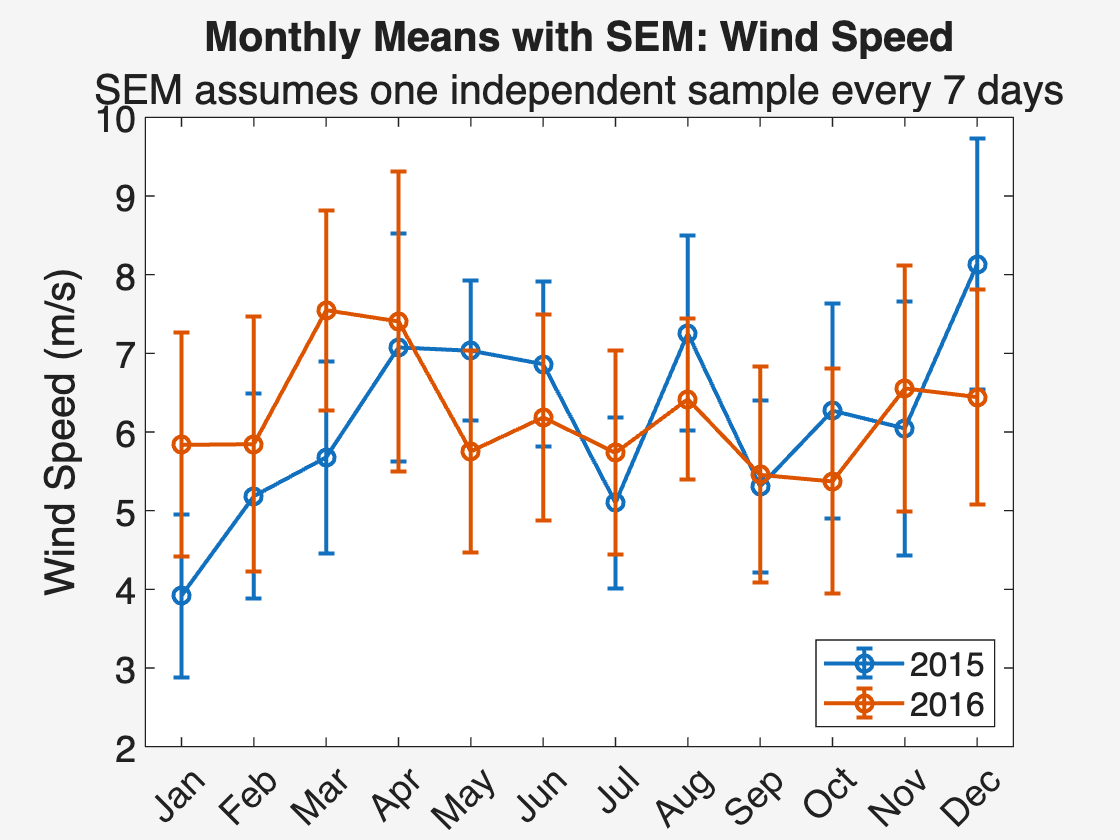

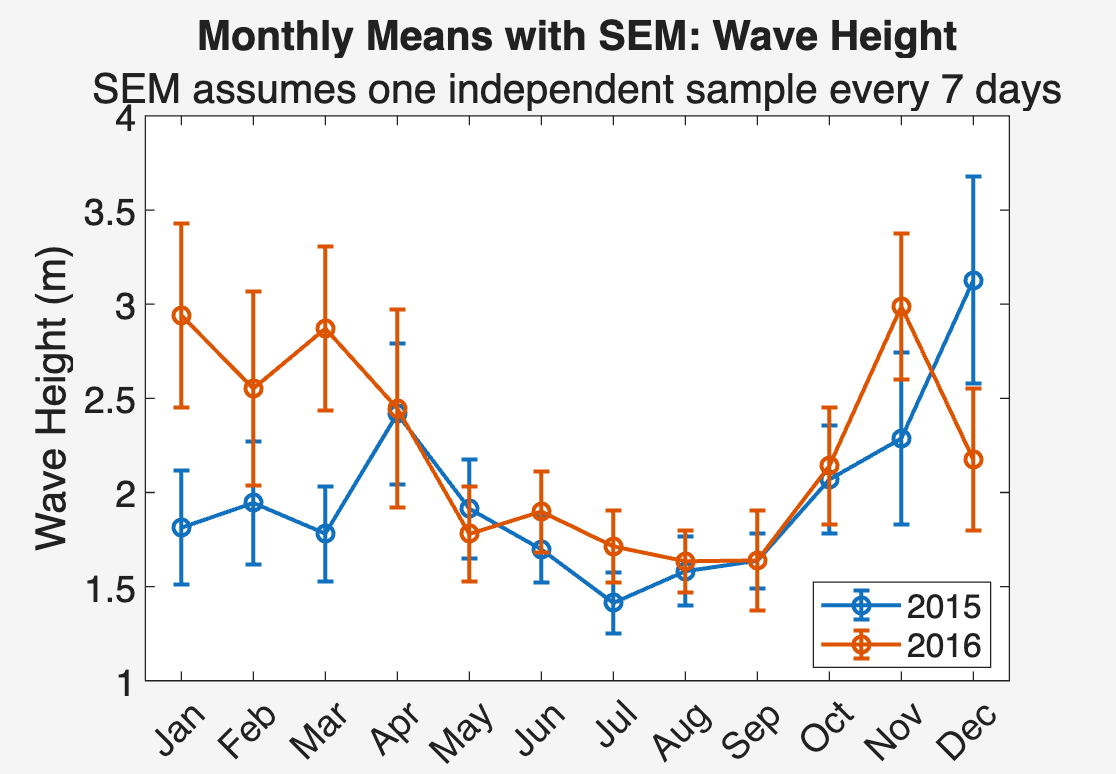

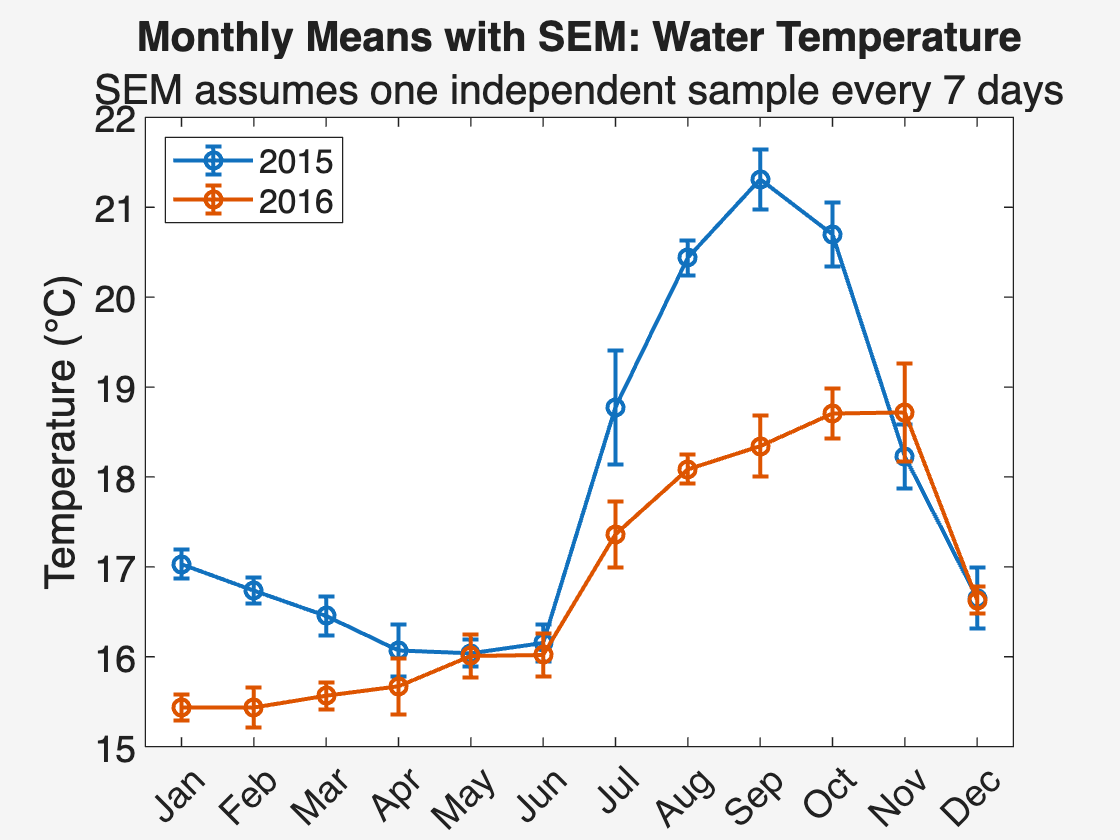

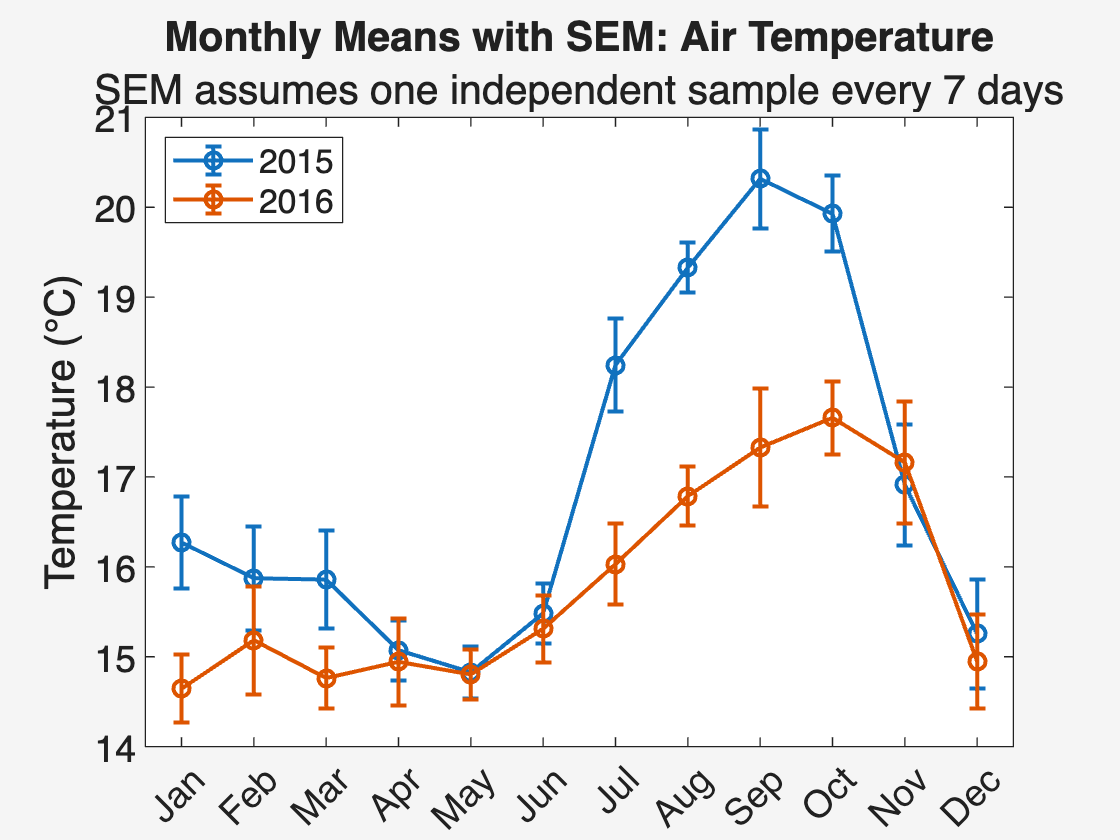

In [68]:
% Plotting time
figure(1); clf;
errorbar(1:12, m_mean_wspd(:,1), m_sem_wspd(:,1),'-o', 'LineWidth', 1.5, 'DisplayName', '2015');
hold on
errorbar(1:12, m_mean_wspd(:,2), m_sem_wspd(:,2),'-o', 'LineWidth', 1.5, 'DisplayName', '2016');
legend('Location','best')
xticks(1:1:12)
xlim([0.5 12.5])
xticklabels({'Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'});
ylabel('Wind Speed (m/s)')
title('Monthly Means with SEM: Wind Speed')
subtitle('SEM assumes one independent sample every 7 days') 
hold off;

figure(2); clf;
errorbar(1:12, m_mean_wvht(:,1), m_sem_wvht(:,1),'-o', 'LineWidth', 1.5, 'DisplayName', '2015');
hold on
errorbar(1:12, m_mean_wvht(:,2), m_sem_wvht(:,2),'-o', 'LineWidth', 1.5, 'DisplayName', '2016');
legend('Location','best')
xticks(1:1:12)
xlim([0.5 12.5])
xticklabels({'Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'});
ylabel('Wave Height (m)')
title('Monthly Means with SEM: Wave Height')
subtitle('SEM assumes one independent sample every 7 days') 
hold off

figure(3); clf;
errorbar(1:12, m_mean_wtmp(:,1), m_sem_wtmp(:,1),'-o', 'LineWidth', 1.5, 'DisplayName', '2015');
hold on
errorbar(1:12, m_mean_wtmp(:,2), m_sem_wtmp(:,2),'-o', 'LineWidth', 1.5, 'DisplayName', '2016');
legend('Location','best')
xticks(1:1:12)
xlim([0.5 12.5])
xticklabels({'Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'});
ylabel('Temperature (°C)')
title('Monthly Means with SEM: Water Temperature')
subtitle('SEM assumes one independent sample every 7 days') 
hold off

figure(4); clf;
errorbar(1:12, m_mean_atmp(:,1), m_sem_atmp(:,1),'-o', 'LineWidth', 1.5, 'DisplayName', '2015');
hold on
errorbar(1:12, m_mean_atmp(:,2), m_sem_atmp(:,2),'-o', 'LineWidth', 1.5, 'DisplayName', '2016');
legend('Location','best')
xticks(1:1:12)
xlim([0.5 12.5])
xticklabels({'Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'});
ylabel('Temperature (°C)')
title('Monthly Means with SEM: Air Temperature')
subtitle('SEM assumes one independent sample every 7 days') 
hold off

In [79]:
%% 3: Least-squares fit. 
% Treating the two years separately, least-squares fit a mean
% and an annual cycle to the four data records. 

%% What is the mean, and what is the amplitude of the annual cycle? 
% (Total amplitude should be determined from the square root of the sum of the squares of the sine and cosine amplitudes.) 
% The means and amplitudes are found below for each variable and year.
years = [2015, 2016];
vars  = {'wspd','wvht','wtmp','atmp'};
names = {'Wind Speed','Wave Height','Water Temperature','Air Temperature'};
units = {'m/s','m','°C','°C'};

for k = 1:numel(years)
    yrField = sprintf('yr_%d', years(k));
    fprintf('\n--- %d ---\n', years(k));

    for v = 1:numel(vars)
        result = fitResults.(vars{v}).(yrField);

        fprintf('%s: Mean = %.3f %s, Annual amplitude = %.3f %s\n',names{v}, result.mean, units{v},result.amplitude, units{v});
    end
end
 

%% Are the fitted coefficients similar for the two years?
% No not particularly. They have fairly different values for the various coefficients. 
% That is what I expected at least, as from the figures above the data was widely varied from eachother. 

for k = 1:numel(years)
    yrField = sprintf('yr_%d', years(k));
    fprintf('\n--- %d ---\n', years(k));

    for v = 1:numel(vars)
        result = fitResults.(vars{v}).(yrField);

        fprintf('%s: Cos Coef = %.3f %s, Sin Coef = %.3f %s\n',names{v}, result.cosCoef, units{v},result.sinCoef, units{v});
    end
end


--- 2015 ---
Wind Speed: Mean = 6.161 m/s, Annual amplitude = 0.372 m/s
Wave Height: Mean = 1.968 m, Annual amplitude = 0.369 m
Water Temperature: Mean = 17.892 °C, Annual amplitude = 2.415 °C
Air Temperature: Mean = 16.957 °C, Annual amplitude = 2.333 °C

--- 2016 ---
Wind Speed: Mean = 6.213 m/s, Annual amplitude = 0.435 m/s
Wave Height: Mean = 2.229 m, Annual amplitude = 0.570 m
Water Temperature: Mean = 16.835 °C, Annual amplitude = 1.690 °C
Air Temperature: Mean = 15.795 °C, Annual amplitude = 1.395 °C

--- 2015 ---
Wind Speed: Cos Coef = -0.372 m/s, Sin Coef = -0.014 m/s
Wave Height: Cos Coef = 0.368 m, Sin Coef = 0.034 m
Water Temperature: Cos Coef = -0.426 °C, Sin Coef = -2.377 °C
Air Temperature: Cos Coef = -0.543 °C, Sin Coef = -2.269 °C

--- 2016 ---
Wind Speed: Cos Coef = -0.026 m/s, Sin Coef = 0.434 m/s
Wave Height: Cos Coef = 0.516 m, Sin Coef = 0.243 m
Water Temperature: Cos Coef = -0.210 °C, Sin Coef = -1.677 °C
Air Temperature: Cos Coef = -0.182 °C, Sin Coef = -1.383 

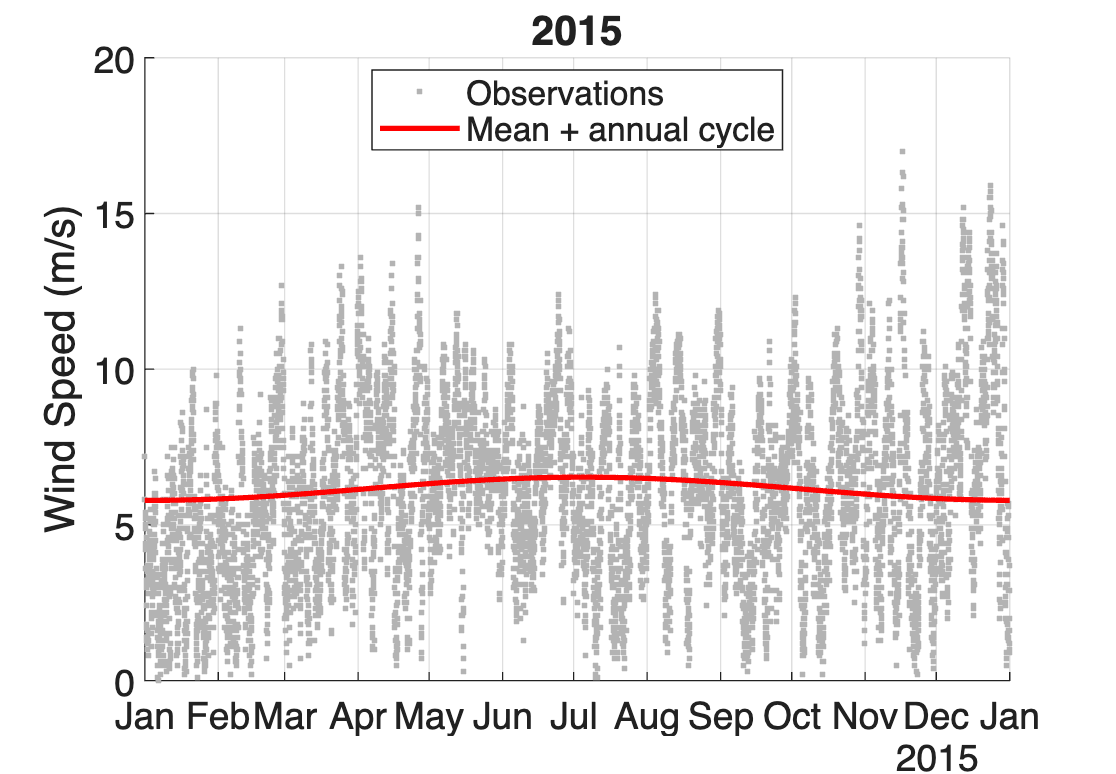

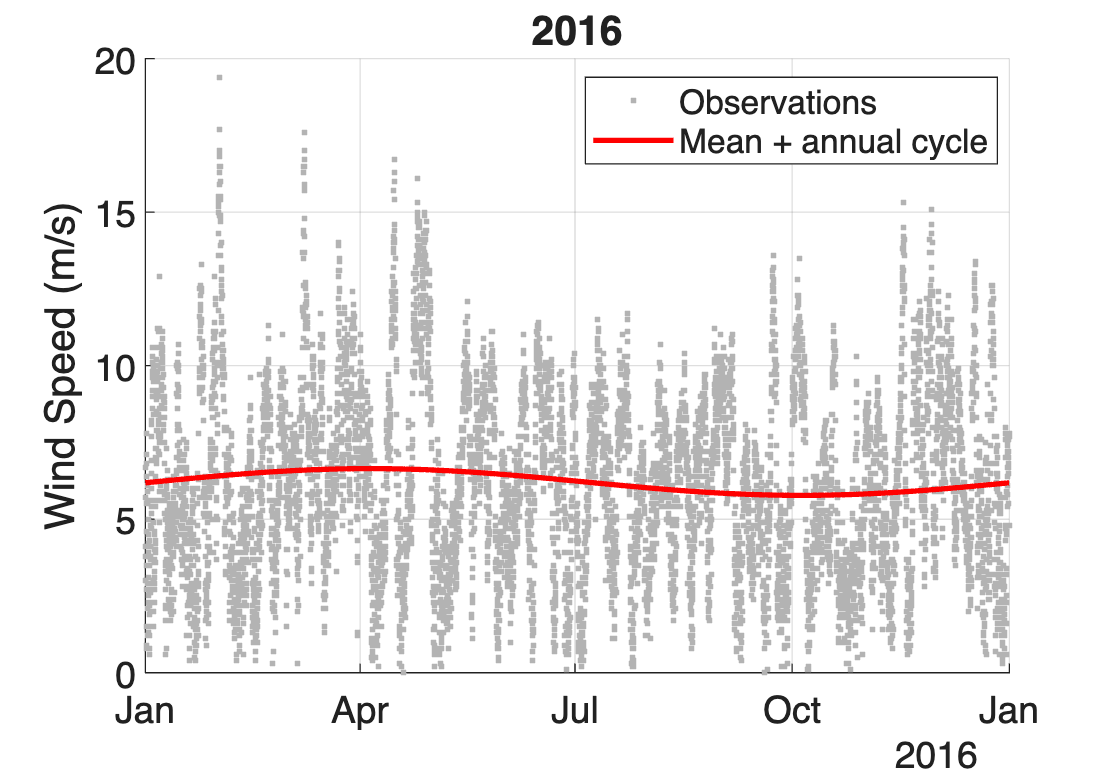

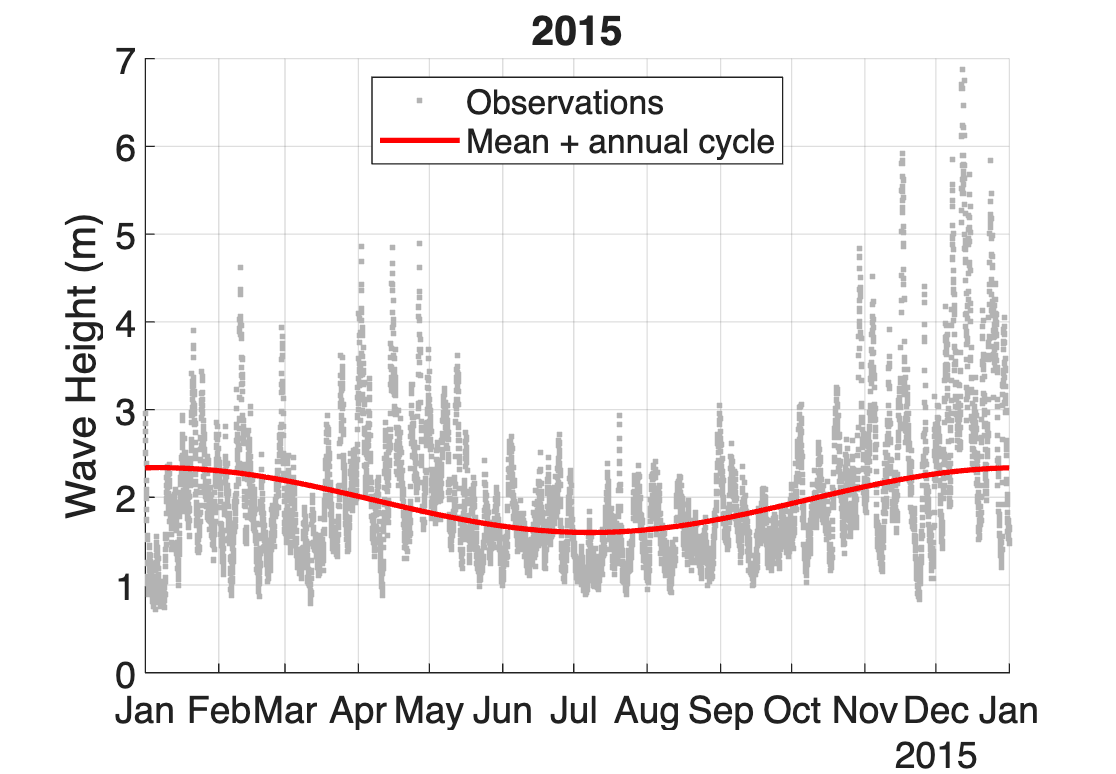

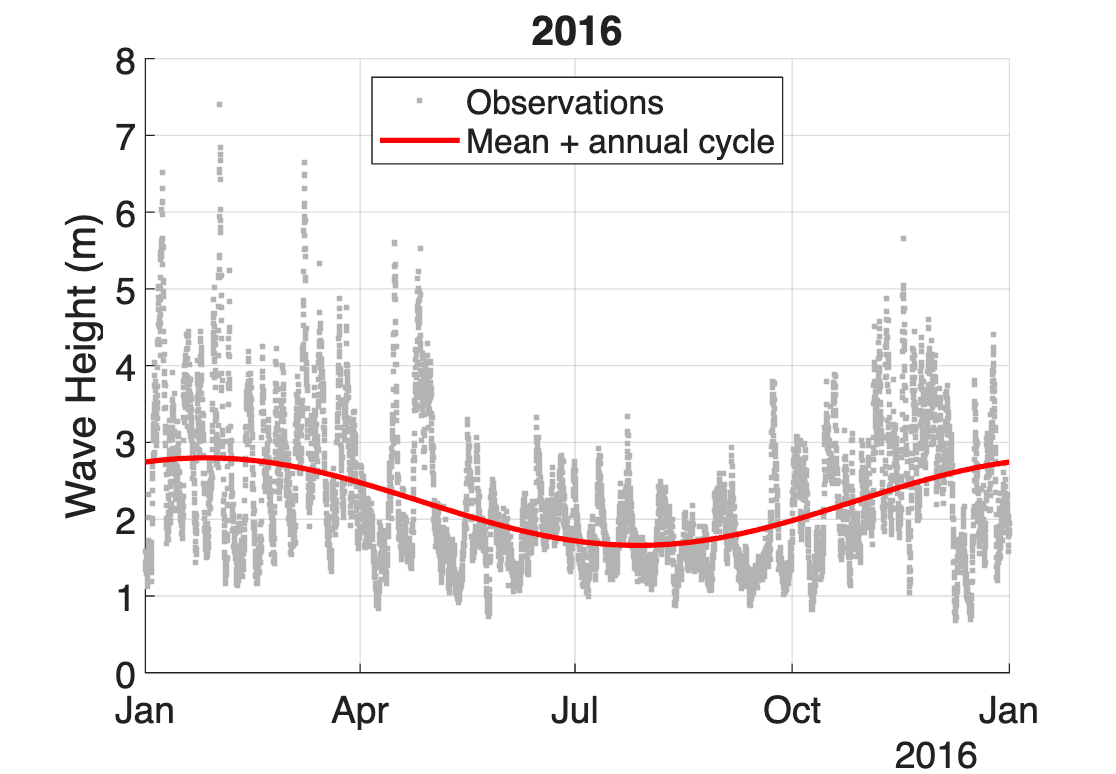

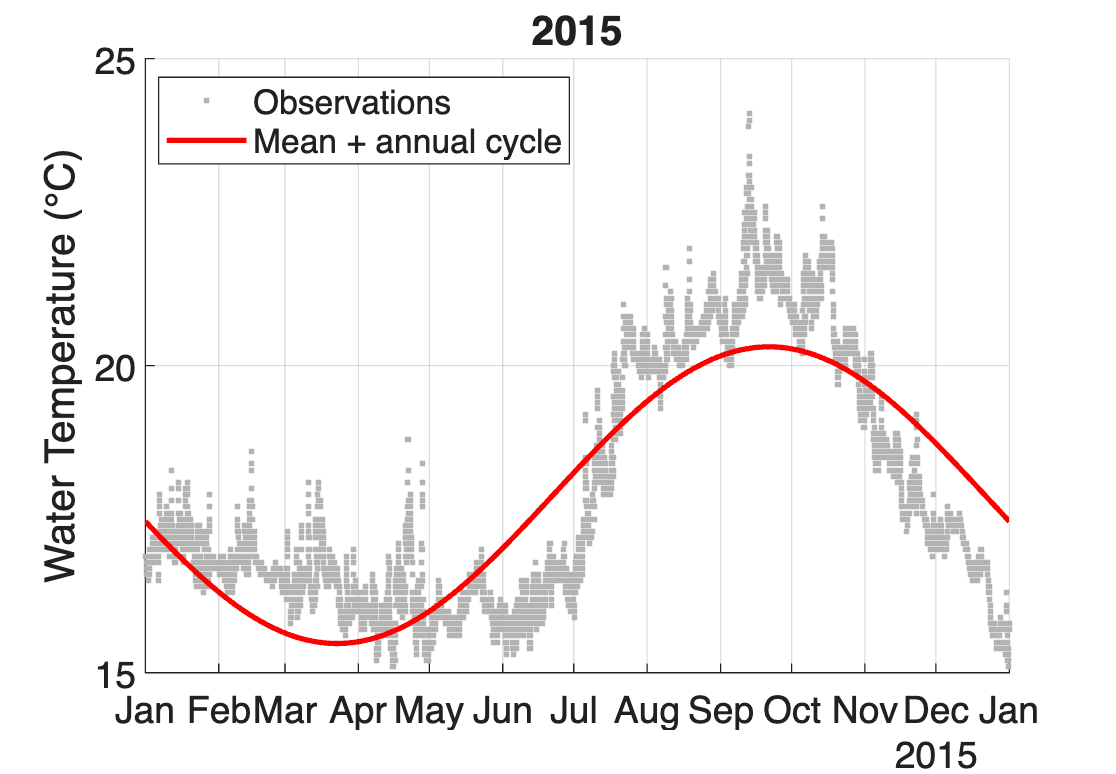

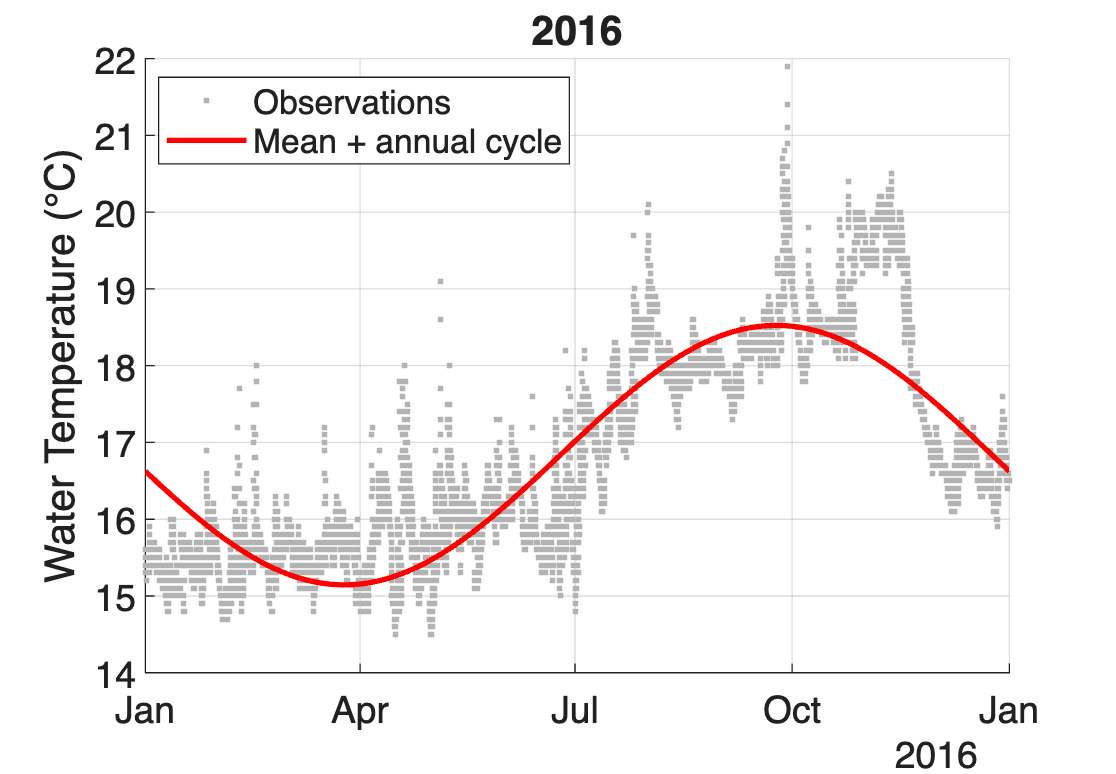

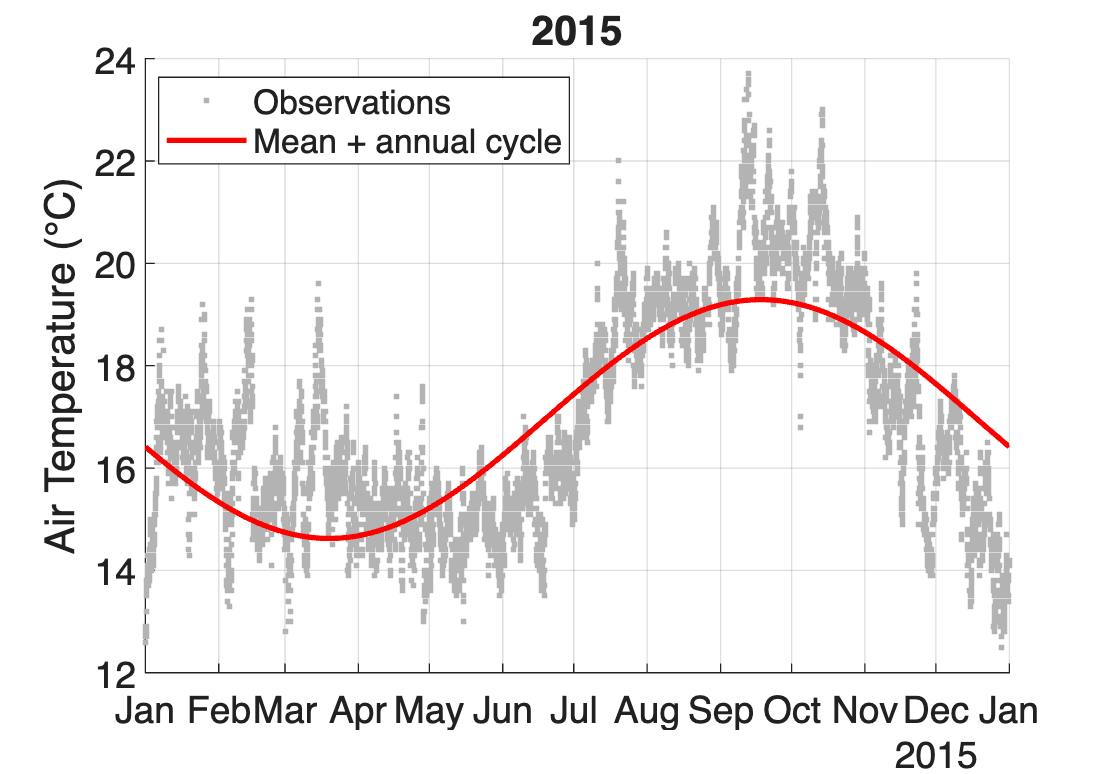

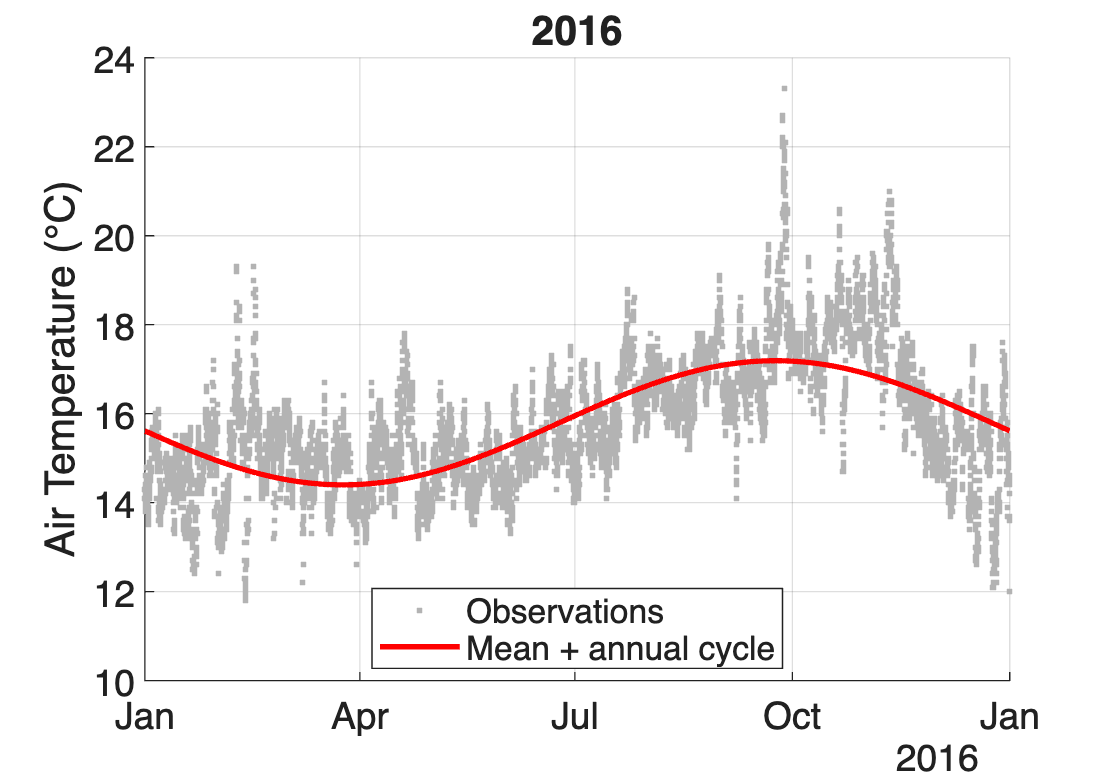

In [76]:
years = [2015, 2016];
vars  = {'wspd','wvht','wtmp','atmp'};
names = {'Wind Speed','Wave Height','Water Temperature','Air Temperature'};
units = {'m/s','m','°C','°C'};
fitResults = struct();

for v = 1:numel(vars)
    for k = 1:numel(years)
        figure;
        hold on;

        x = T.(vars{v});
        idx = year(T.date) == years(k) & isfinite(x);

        dates = T.date(idx);
        values = x(idx);
        dates = dates(:);
        values = values(:);

        t0 = datetime(years(k),1,1, 'TimeZone',T.date.TimeZone);
        t1 = datetime(years(k)+1,1,1, 'TimeZone',T.date.TimeZone);

        t = seconds(dates - t0) / seconds(t1 - t0);

        G = [ones(size(t)), cos(2*pi*t), sin(2*pi*t)];

        coef = G \ values;

        yrField = sprintf('yr_%d', years(k));
        fitResults.(vars{v}).(yrField).mean = coef(1);
        fitResults.(vars{v}).(yrField).cosCoef = coef(2);
        fitResults.(vars{v}).(yrField).sinCoef = coef(3);
        fitResults.(vars{v}).(yrField).amplitude = hypot(coef(2),coef(3));

        tFit = linspace(0,1,366)';
        datesFit = t0 + seconds(tFit * seconds(t1 - t0));
        yFit = coef(1) + coef(2)*cos(2*pi*tFit) + coef(3)*sin(2*pi*tFit);

        plot(dates, values, '.', 'Color',[0.7 0.7 0.7],'DisplayName','Observations');
        plot(datesFit, yFit, 'r-', 'LineWidth',2,'DisplayName','Mean + annual cycle');

        xlim([t0 t1]);
        xtickformat('MMM');
        ylabel(sprintf('%s (%s)', names{v}, units{v}));
        title(sprintf('%d', years(k)));
        grid on;
        
        legend('Location','best');
    end
end

In [83]:
%% 4: Least-squares fit a semi-annual cycle. 
% Augment your annual cycle least- squares fit with a semi-annual cycle.

%% What is the amplitude of the semi-annual cycle? 
% Amplitudes and means are listed below.
years = [2015, 2016];
vars  = {'wspd','wvht','wtmp','atmp'};
names = {'Wind Speed','Wave Height','Water Temperature','Air Temperature'};
units = {'m/s','m','°C','°C'};

for k = 1:numel(years)
    yrField = sprintf('yr_%d', years(k));
    fprintf('\n--- %d ---\n', years(k));

    for v = 1:numel(vars)
        result = fitResults2.(vars{v}).(yrField);

        fprintf('%s: Mean = %.3f %s, Semi-annual amplitude = %.3f %s\n',names{v}, result.mean, units{v},result.semiAmplitude, units{v});
    end
end


% Does the augmented fit give you a different annual cycle?
% It does! After changing to a semi-annual cycle, it fits the data slightly better compared to the regular annual cycle. 
% This can especially be seen in the wind and wave data. The first annual cycle didn't represent the data nearly as closely.


--- 2015 ---
Wind Speed: Mean = 6.161 m/s, Semi-annual amplitude = 0.786 m/s
Wave Height: Mean = 1.970 m, Semi-annual amplitude = 0.313 m
Water Temperature: Mean = 17.891 °C, Semi-annual amplitude = 1.214 °C
Air Temperature: Mean = 16.957 °C, Semi-annual amplitude = 1.332 °C

--- 2016 ---
Wind Speed: Mean = 6.213 m/s, Semi-annual amplitude = 0.182 m/s
Wave Height: Mean = 2.229 m, Semi-annual amplitude = 0.061 m
Water Temperature: Mean = 16.835 °C, Semi-annual amplitude = 0.511 °C
Air Temperature: Mean = 15.795 °C, Semi-annual amplitude = 0.618 °C


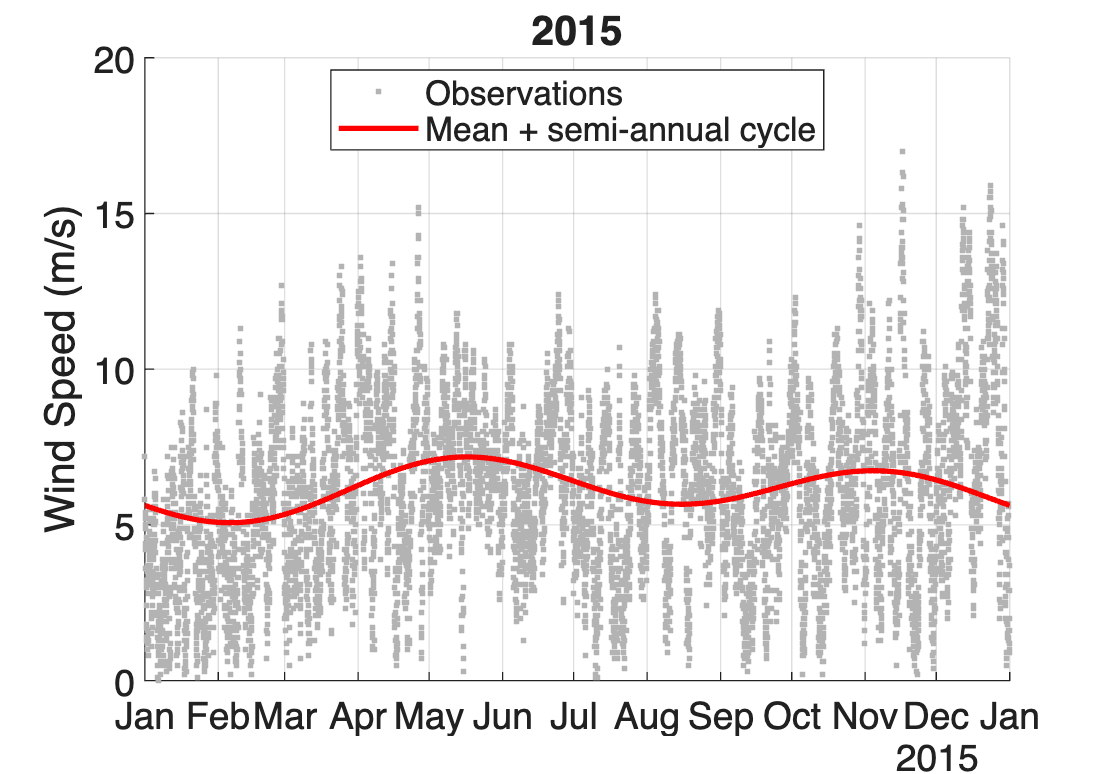

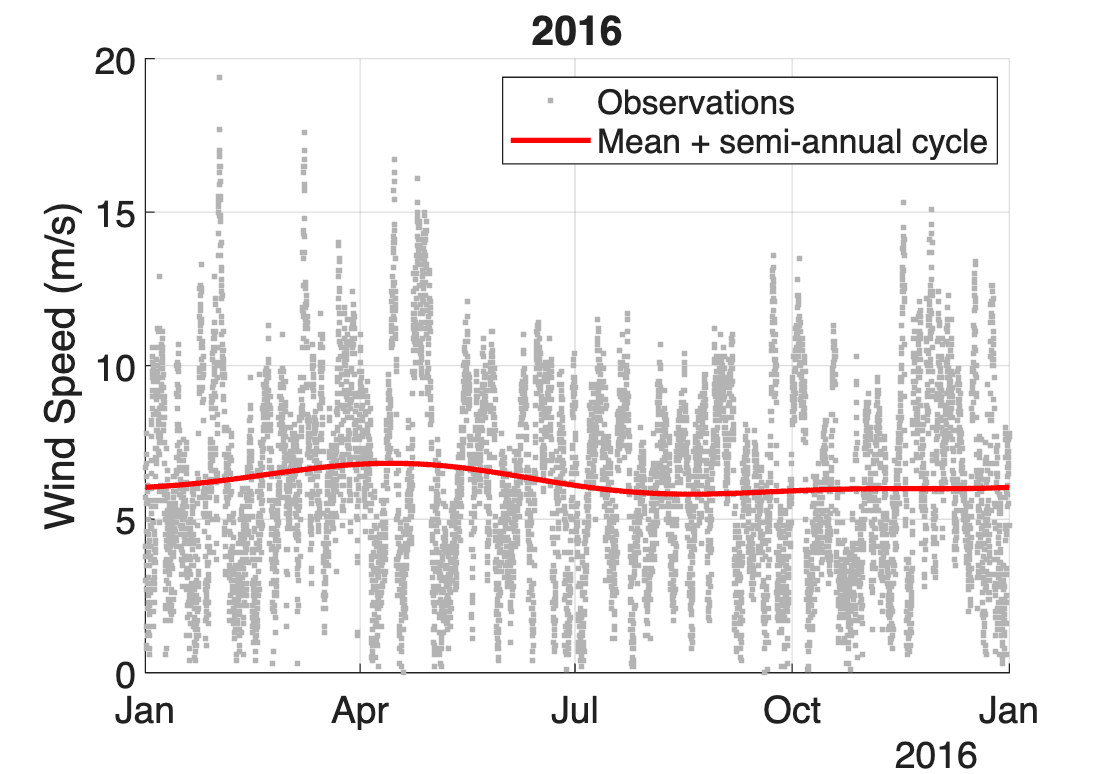

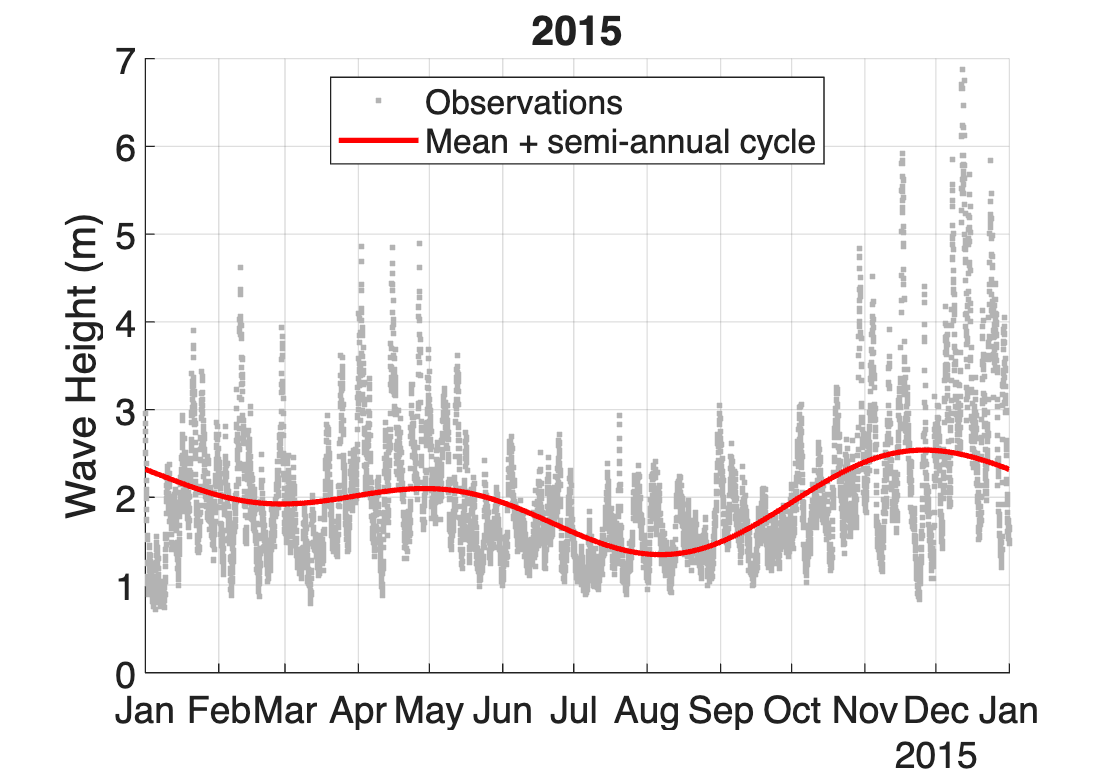

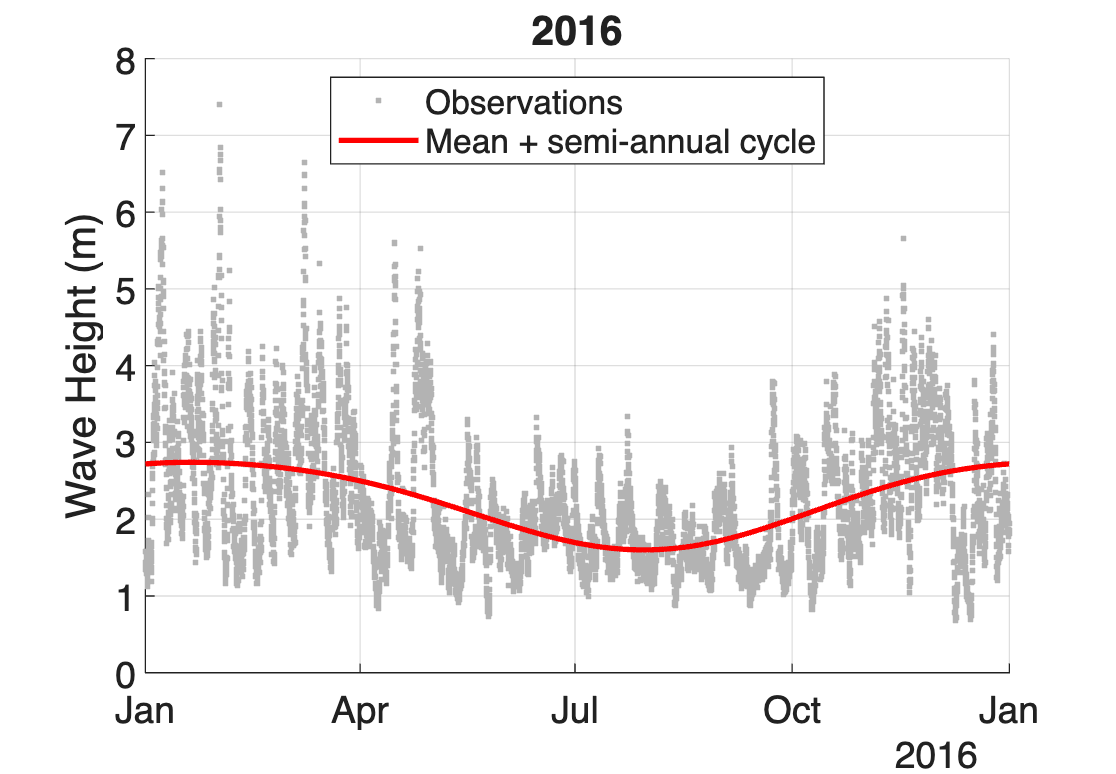

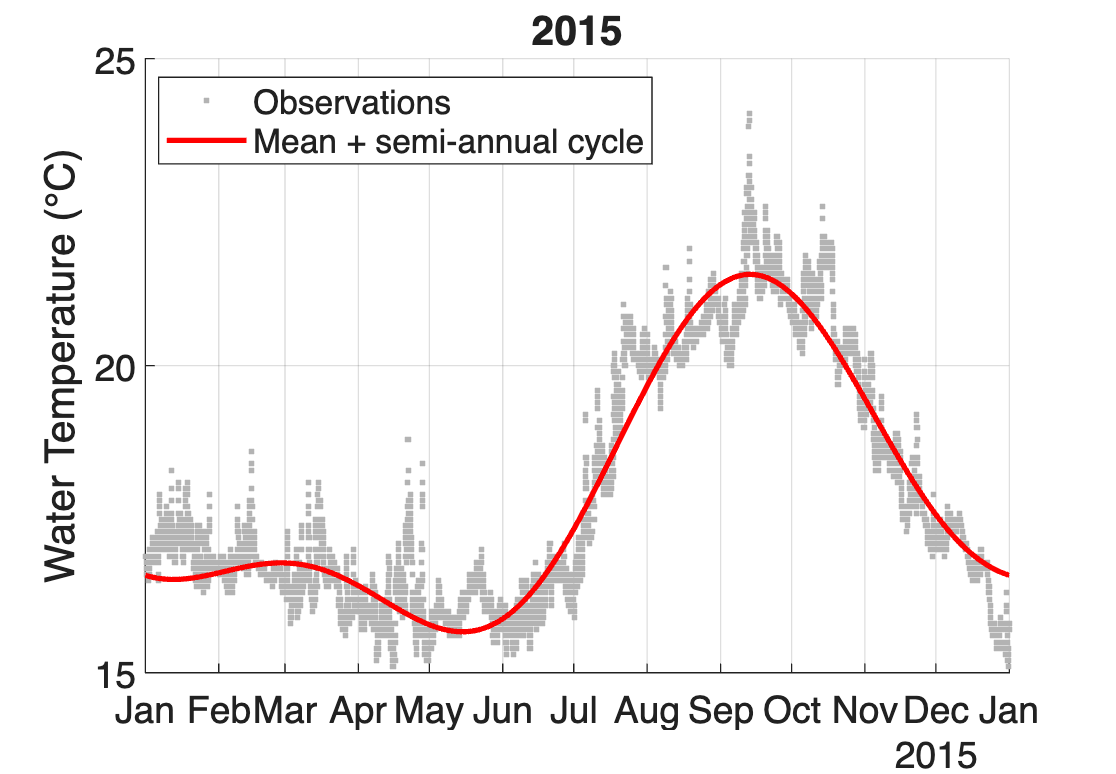

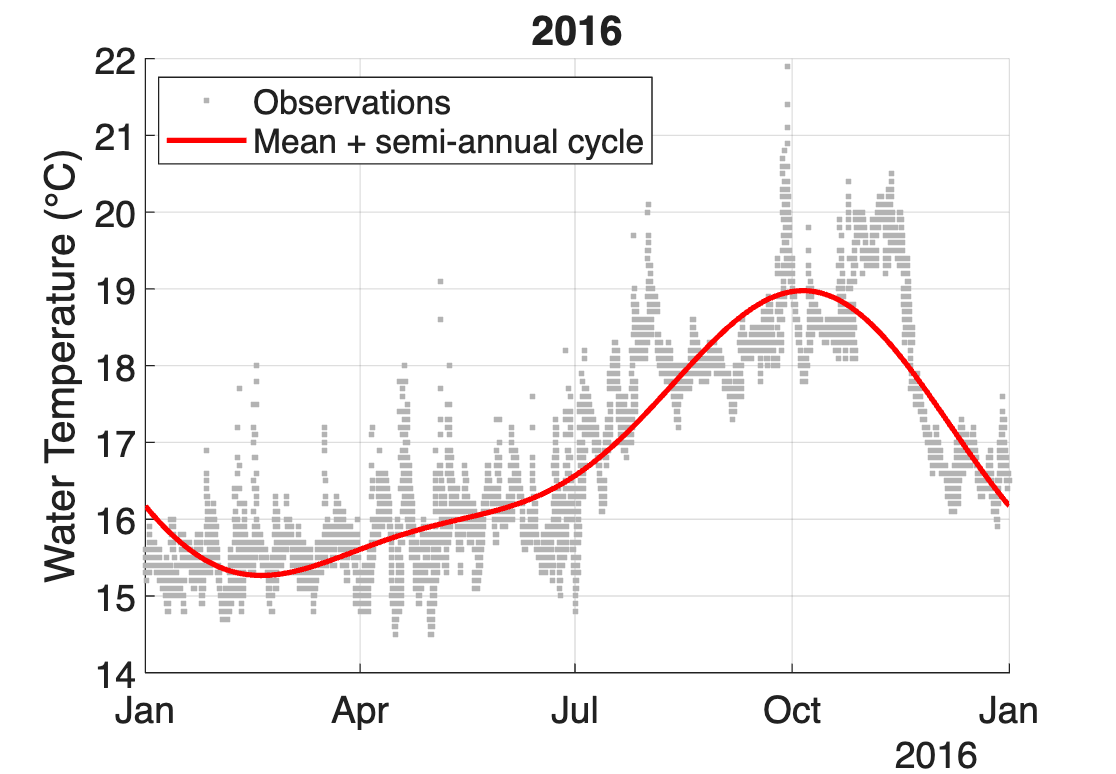

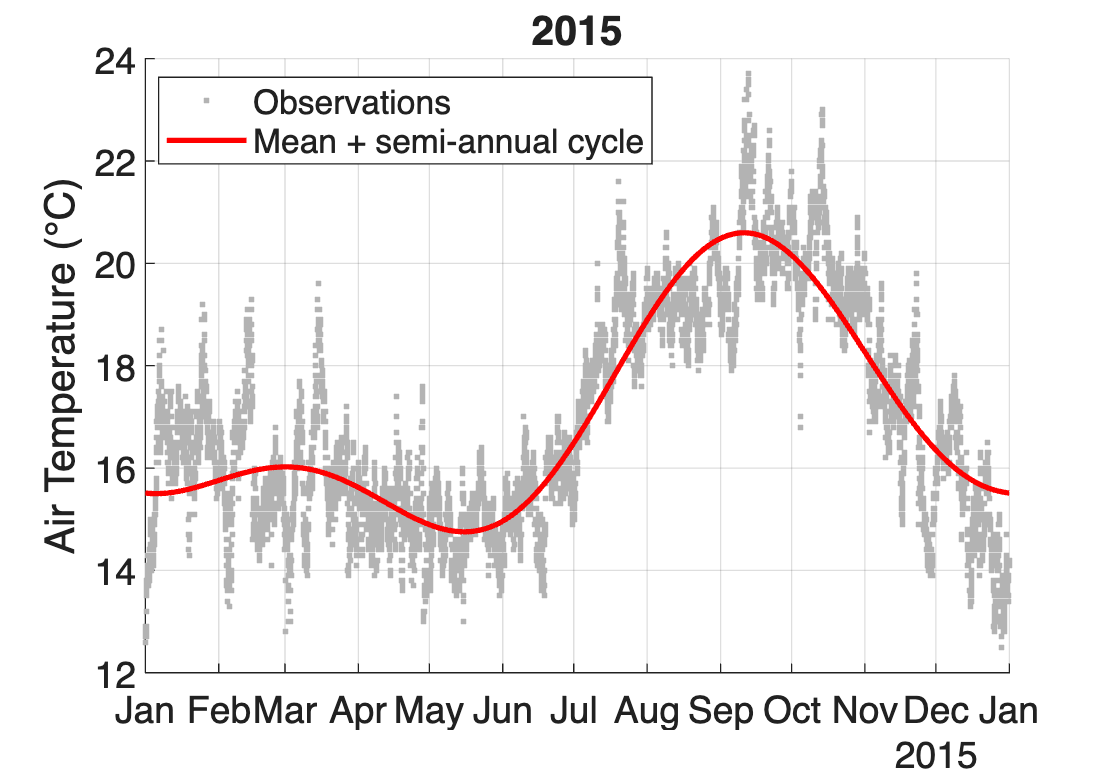

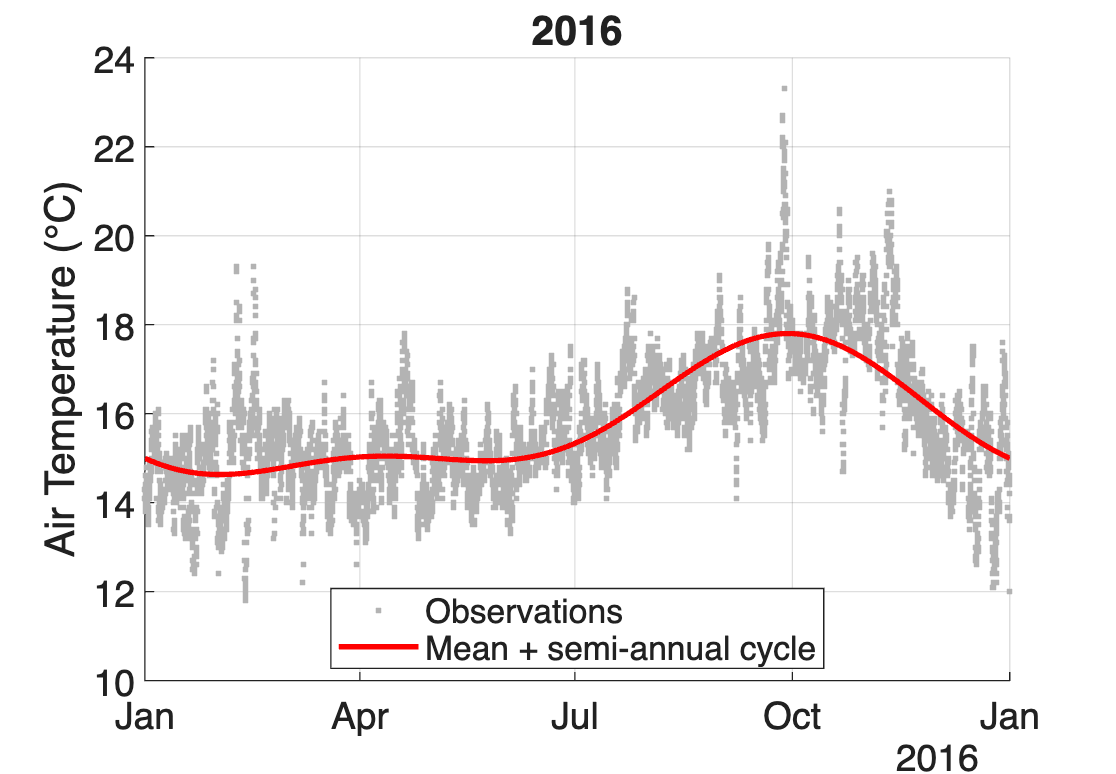

In [81]:
years = [2015, 2016];
vars  = {'wspd','wvht','wtmp','atmp'};
names = {'Wind Speed','Wave Height','Water Temperature','Air Temperature'};
units = {'m/s','m','°C','°C'};
fitResults = struct();

for v = 1:numel(vars)
    for k = 1:numel(years)
        figure;
        hold on;

        x = T.(vars{v});
        idx = year(T.date) == years(k) & isfinite(x);

        dates = T.date(idx);
        values = x(idx);
        dates = dates(:);
        values = values(:);

        t0 = datetime(years(k),1,1, 'TimeZone',T.date.TimeZone);
        t1 = datetime(years(k)+1,1,1, 'TimeZone',T.date.TimeZone);

        t = seconds(dates - t0) / seconds(t1 - t0);

        G = [ones(size(t)), cos(2*pi*t), sin(2*pi*t), cos(4*pi*t), sin(4*pi*t)];
        
        coef = G \ values;

        yrField = sprintf('yr_%d', years(k));

        fitResults2.(vars{v}).(yrField).mean = coef(1);
        fitResults2.(vars{v}).(yrField).cosCoef = coef(2);
        fitResults2.(vars{v}).(yrField).sinCoef = coef(3);
        fitResults2.(vars{v}).(yrField).amplitude = hypot(coef(2),coef(3));
        fitResults2.(vars{v}).(yrField).semiCosCoef = coef(4);
        fitResults2.(vars{v}).(yrField).semiSinCoef = coef(5);
        fitResults2.(vars{v}).(yrField).semiAmplitude = hypot(coef(4),coef(5));

        tFit = linspace(0,1,366)';
        datesFit = t0 + seconds(tFit * seconds(t1 - t0));
        yFit = coef(1) + coef(2)*cos(2*pi*tFit) + coef(3)*sin(2*pi*tFit) + coef(4)*cos(4*pi*tFit) + coef(5)*sin(4*pi*tFit);

        plot(dates, values, '.', 'Color',[0.7 0.7 0.7],'DisplayName','Observations');
        plot(datesFit, yFit, 'r-', 'LineWidth',2,'DisplayName','Mean + semi-annual cycle');

        xlim([t0 t1]);
        xtickformat('MMM');
        ylabel(sprintf('%s (%s)', names{v}, units{v}));
        title(sprintf('%d', years(k)));
        grid on;
        
        legend('Location','best');
    end
end

In [90]:
%% 5: χ2 and the misfit.
%% What is the squared misfit of your least-squares fits?
% See results below.

% In other words, the misfit for each point should be roughly equal to the uncertainty.
% We lose a degree of freedom for each function that we use to fit. 
%% How much does the misfit change if you fit with an annual cycle only or with an annual plus semi-annnual cycle?
% We can see that the misfit reduces slightly when we include the semi-annual cycle. For instance, the atmospheric temp
% goes from a misfit of 13.05 to 3.53 when we include the semi-annual cycle. 

%% Use the χ2 distribution to evaluate whether your fits are improved by adding the semi-annual fit?
% For the majority of the data, there are noticable improvements by adding the semi-annual fit. 
% If we look at the p-value for the different years / vars, we can see that majority of them fall below the 0.05 threshold.

%% On the basis of the χ2 distribution, are you overfitting the data, or choosing the wrong model for your data?
% In this case, I believe taht the data is being overfitted. Especially when considering the large quantity of data points.

%% How would your results change if you assumed that you had one independent sample 
%% (i.e. one degree of freedom) per day, instead of one per week?
% We could expect a much larger Chi^2 value as the noise of the data increases greatly. 
% We can see this in the previous problem (#4) when viewing the different figures.
% Using all of the available data vs. using just the means or reducing sampling to weekly, reduces the noise from the data.
% This also means that it may not be a complete representation of the actual observations. 

In [88]:
vars  = {'wspd','wvht','wtmp','atmp'};
years = [2015, 2016];
flags = [99, 99, 999, 999];

t = ((1:12)' - 0.5)/12;
G1 = [ones(12,1), cos(2*pi*t), sin(2*pi*t)];
G2 = [G1, cos(4*pi*t), sin(4*pi*t)];

for v = 1:numel(vars)

    x = T.(vars{v});
    x(x == flags(v)) = NaN;

    for k = 1:numel(years)

        m_mean = nan(12,1);
        m_sem  = nan(12,1);

        for m = 1:12
            idx = year(T.date) == years(k) & month(T.date) == m;
            values = x(idx);
            values = values(isfinite(values));

            if numel(values) > 1
                nIndependent = min(numel(values), eomday(years(k),m)/7);

                m_mean(m) = mean(values);
                m_sem(m) = std(values)/sqrt(nIndependent);
            end
        end

        valid = isfinite(m_mean) & isfinite(m_sem) & m_sem > 0;
        y = m_mean(valid);
        sigma = m_sem(valid);
        A = G1(valid,:);
        B = G2(valid,:);

        N = numel(y);

        c1 = (A ./ sigma) \ (y ./ sigma);
        c2 = (B ./ sigma) \ (y ./ sigma);

        chiAnnual = sum(((y - A*c1) ./ sigma).^2);
        chiBoth   = sum(((y - B*c2) ./ sigma).^2);

        df = [N-3, N-5];
        deltaChi = max(0, chiAnnual - chiBoth);
        p = chi2cdf(deltaChi, 2, 'upper');

        rangeAnnual = chi2inv([0.025, 0.975], df(1));
        rangeBoth   = chi2inv([0.025, 0.975], df(2));

        fprintf('\n%s — %d\n', vars{v}, years(k));
        fprintf('Annual chi²: %.2f; expected 95%% range: %.2f–%.2f\n', chiAnnual, rangeAnnual(1), rangeAnnual(2));
        fprintf('Annual + semiannual chi²: %.2f; range: %.2f–%.2f\n', chiBoth, rangeBoth(1), rangeBoth(2));
        fprintf('Misfit reduction: %.2f; p-value: %.4g\n', deltaChi, p);
        fprintf('Daily independence: chi² = %.2f and %.2f; p = %.4g\n', 7*chiAnnual, 7*chiBoth, chi2cdf(7*deltaChi, 2, 'upper'));
    end
end


wspd — 2015
Annual chi²: 9.05; expected 95% range: 2.70–19.02
Annual + semiannual chi²: 6.19; range: 1.69–16.01
Misfit reduction: 2.87; p-value: 0.2386
Daily independence: chi² = 63.37 and 43.31; p = 4.406e-05

wspd — 2016
Annual chi²: 2.03; expected 95% range: 2.70–19.02
Annual + semiannual chi²: 1.86; range: 1.69–16.01
Misfit reduction: 0.16; p-value: 0.9217
Daily independence: chi² = 14.18 and 13.04; p = 0.5653

wvht — 2015
Annual chi²: 10.84; expected 95% range: 2.70–19.02
Annual + semiannual chi²: 5.53; range: 1.69–16.01
Misfit reduction: 5.30; p-value: 0.07055
Daily independence: chi² = 75.86 and 38.74; p = 8.702e-09

wvht — 2016
Annual chi²: 6.57; expected 95% range: 2.70–19.02
Annual + semiannual chi²: 6.47; range: 1.69–16.01
Misfit reduction: 0.10; p-value: 0.9517
Daily independence: chi² = 45.98 and 45.29; p = 0.7071

wtmp — 2015
Annual chi²: 141.39; expected 95% range: 2.70–19.02
Annual + semiannual chi²: 16.32; range: 1.69–16.01
Misfit reduction: 125.07; p-value: 6.94e-28
